# 04 · CO3: Topic modelling & multilingual NLP (7 marks)
* **Topic modelling:** LDA (gensim) with the number of topics chosen by **C_v coherence**, compared with NMF,
  and linked to difficulty (which topics are hardest?).
* **Multilingual NLP:** Hindi & Marathi questions → language identification → Indic normalisation and
  tokenisation → **local neural machine translation** (MarianMT, OPUS-MT) → difficulty prediction.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
REPORTS = ROOT / 'reports'; FIG = REPORTS / 'figures'
def show(name): display(Image(filename=str(FIG / name)))
def rj(name): return json.loads((REPORTS / name).read_text())

## Topic modelling

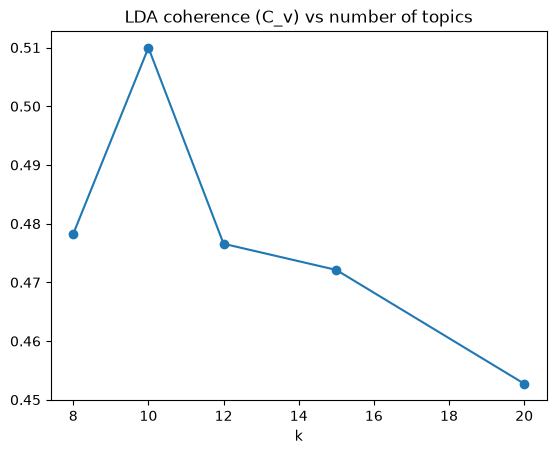

best k = 10 | LDA C_v = 0.51 | NMF C_v = 0.56


In [2]:
tp = rj('topics.json')
ck = pd.Series(tp['lda_coherence_by_k']); ck.index = ck.index.astype(int)
ck.plot(marker='o', title='LDA coherence (C_v) vs number of topics'); plt.xlabel('k'); plt.show()
print('best k =', tp['best_k'], '| LDA C_v =', round(tp['lda_coherence'],3), '| NMF C_v =', round(tp['nmf_coherence'],3))

In [3]:
lt = pd.DataFrame(tp['lda_topics']); lt['top_words'] = lt.top_words.map(lambda w: ', '.join(w[:8]))
lt.sort_values('mean_score')[['topic','top_words','n_questions','mean_score','pct_hard','main_sources']]

,topic,top_words,n_questions,mean_score,pct_hard,main_sources
6,6,"water, plant, energy, follow, type, change, cell, produce",4032,38.0,0.059,"{'arc': 1478, 'sciq': 744, 'openbookqa': 559}"
4,4,"hour, day, take, work, minute, per, long, time",1498,38.4,0.093,"{'race': 269, 'gsm8k': 221, 'commonsense_qa': 212}"
9,9,"many, much, buy, cost, total, sell, ball, money",1602,38.5,0.099,"{'gsm8k': 619, 'math': 222, 'race': 170}"
3,3,"student, many, people, school, first, class, child, study",1953,42.8,0.177,"{'race': 642, 'math': 358, 'gsm8k': 258}"
0,0,"follow, state, question, information, refer, accord, may, law",2375,45.4,0.160,"{'mmlu': 911, 'race': 563, 'arc': 344}"
2,2,"car, man, defendant, year, light, old, woman, tell",1532,45.6,0.272,"{'race': 482, 'mmlu': 469, 'commonsense_qa': 200}"
1,1,"digit, foot, year, many, rock, base, bill, age",1010,49.2,0.277,"{'math': 334, 'arc': 143, 'gsm8k': 129}"
7,7,"year, company, land, pay, build, property, city, owner",1014,54.0,0.385,"{'mmlu': 417, 'race': 189, 'math': 137}"
8,8,"real, circ, function, enter, compute, equation, sin, root",1477,69.5,0.622,"{'math': 1177, 'mmlu': 90, 'race': 65}"
5,5,"integer, point, sqrt, positive, triangle, diagram, square, angle",3507,72.5,0.675,"{'math': 3001, 'mmlu': 170, 'arc': 88}"


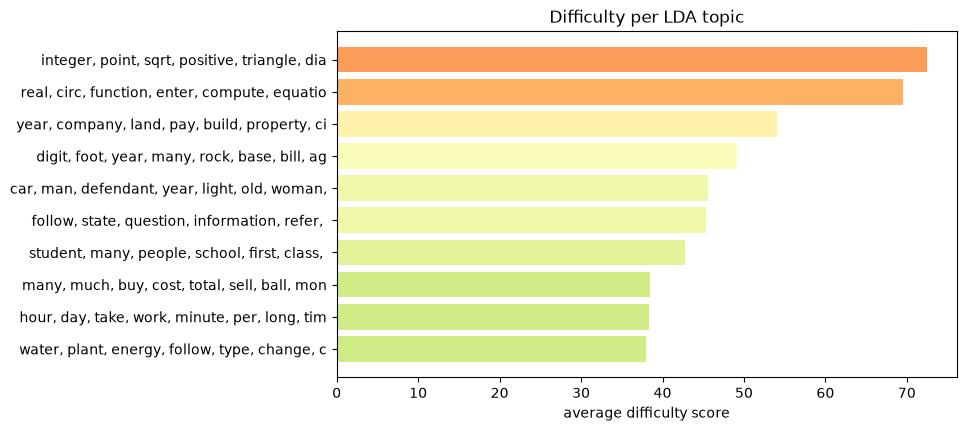

In [4]:
lt2 = lt.sort_values('mean_score')
plt.figure(figsize=(8,4.5)); plt.barh(lt2.top_words.str.slice(0,45), lt2.mean_score, color=plt.cm.RdYlGn_r(lt2.mean_score/100))
plt.xlabel('average difficulty score'); plt.title('Difficulty per LDA topic'); plt.show()

In [5]:
pd.DataFrame(tp['nmf_topics']).assign(top_words=lambda d: d.top_words.map(', '.join))

,topic,top_words,n_questions,mean_score
0,0,"integer, positive, smallest, many, possible, divisor, factor, sum, less, multiple",912,70.8
1,1,"sqrt, simplify, evaluate, form, denominator, rationalize, simplest, expression, write, fraction",423,74.9
2,2,"triangle, angle, diagram, area, abc, point, square, side, length, circ",1542,69.4
3,3,"compute, circ, tan, sin, give, root, infinity, complex, radian, head",312,71.6
4,4,"many, student, water, people, day, year, take, time, plant, want",12195,39.6
5,5,"real, minimum, function, possible, satisfy, root, positive, polynomial, maximum, complex",752,74.2
6,6,"equation, solution, solve, root, point, line, enter, circle, sum, separate",692,68.8
7,7,"follow, expression, except, describe, accord, example, simplify, common, factor, correct",2058,52.3
8,8,"digit, sum, base, three, common, divisible, fraction, multiple, unit, product",879,68.8
9,9,"divide, remainder, sum, quotient, term, sequence, determine, polynomial, prime, less",235,64.8


In [6]:
from src.nlp.topics import topic_of
for q in ['What is the probability of rolling two sixes?', 'Why do plants need sunlight?', 'The passage mainly tells us that']:
    print(topic_of(q), '|', q)

{'topic': 5, 'probability': 0.459, 'top_words': ['integer', 'point', 'sqrt', 'positive', 'triangle', 'diagram'], 'topic_mean_score': 72.5, 'distribution': [(5, 0.459), (1, 0.25), (6, 0.051)]} | What is the probability of rolling two sixes?
{'topic': 6, 'probability': 0.681, 'top_words': ['water', 'plant', 'energy', 'follow', 'type', 'change'], 'topic_mean_score': 38.0, 'distribution': [(6, 0.681)]} | Why do plants need sunlight?
{'topic': 4, 'probability': 0.311, 'top_words': ['hour', 'day', 'take', 'work', 'minute', 'per'], 'topic_mean_score': 38.4, 'distribution': [(4, 0.311), (2, 0.308), (6, 0.064)]} | The passage mainly tells us that


## Multilingual NLP

In [7]:
from src.multilingual.pipeline import detect_language, indic_tokenize, remove_hindi_stopwords, to_english
for q in ['न्यूटन के गति के तीसरे नियम को एक उदाहरण सहित समझाइए।', 'पृथ्वीवर ऋतू का बदलतात?', 'Why do seasons change on Earth?']:
    d = detect_language(q); print(d['name'], '|', d['evidence'], '|', q)

Hindi | {'marathi_markers': 0, 'hindi_markers': 3, 'langdetect': {'hi': 0.9999972068734508}} | न्यूटन के गति के तीसरे नियम को एक उदाहरण सहित समझाइए।
Marathi | {'marathi_markers': 1, 'hindi_markers': 1, 'langdetect': {'mr': 0.99999796893533}} | पृथ्वीवर ऋतू का बदलतात?
English | {'devanagari': 0.0, 'latin': 1.0} | Why do seasons change on Earth?


In [8]:
q = 'न्यूटन के गति के तीसरे नियम को एक उदाहरण सहित समझाइए।'
toks = indic_tokenize(q)
print('tokens          :', toks); print('no stop-words   :', remove_hindi_stopwords(toks))
print('MT → English    :', to_english(q)['english'])

tokens          : ['न्यूटन', 'के', 'गति', 'के', 'तीसरे', 'नियम', 'को', 'एक', 'उदाहरण', 'सहित', 'समझाइए', '.']
no stop-words   : ['न्यूटन', 'गति', 'तीसरे', 'नियम', 'उदाहरण', 'सहित', 'समझाइए', '.']


W1116 23:28:27.945000 60792 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=128) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


MT → English    : Explain Newton's third law with an example.


In [9]:
mm = rj('multilingual_metrics.json')
print('Language-ID accuracy:', mm['language_id_accuracy'])
pd.DataFrame({k:v for k,v in mm.items() if isinstance(v,dict)}).round(3)

Language-ID accuracy: 1.0


,mt_model_selection,selected_models,hi,mr
hi | opus-mt-hi-en,0.486,NaN,NaN,NaN
hi | opus-mt-mul-en,0.280,NaN,NaN,NaN
mr | opus-mt-mr-en,0.083,NaN,NaN,NaN
mr | opus-mt-mul-en,0.339,NaN,NaN,NaN
hi,NaN,Helsinki-NLP/opus-mt-hi-en,NaN,NaN
mr,NaN,Helsinki-NLP/opus-mt-mul-en,NaN,NaN
n,NaN,NaN,24.000,9.000
language_id_accuracy,NaN,NaN,1.000,1.000
corpus_bleu,NaN,NaN,0.486,0.339
score_mae_vs_english,NaN,NaN,2.429,5.756


In [10]:
mp = pd.read_csv(REPORTS/'multilingual_predictions.csv')
mp[['lang','question','english_mt','expected_level','level_mt','score_mt','level_ref','score_ref','bleu']].round(2)

,lang,question,english_mt,expected_level,level_mt,score_mt,level_ref,score_ref,bleu
0,hi,पानी का रासायनिक सूत्र क्या है?,What is the chemical formula of water?,Easy,Easy,23.5,Easy,23.5,1.00
1,hi,भारत की राजधानी क्या है?,What is the capital of India?,Easy,Easy,29.0,Easy,29.0,1.00
2,hi,सूर्य किस दिशा में उगता है?,In what direction does the sun spring?,Easy,Easy,30.9,Easy,33.3,0.38
3,hi,एक सप्ताह में कितने दिन होते हैं?,How many days are there in a week?,Easy,Easy,31.6,Easy,31.6,1.00
4,hi,पौधे अपना भोजन किस प्रक्रिया से बनाते हैं?,By what process do plants plant their food?,Easy,Easy,25.0,Easy,30.9,0.31
5,hi,गाय कौन सा जानवर है?,Which animal is the cow?,Easy,Easy,33.3,Easy,29.0,0.16
6,hi,राम के पास 5 सेब हैं और उसने 2 खा लिए। अब उसके पास कितने सेब बचे हैं?,Ram has 5 apples and he ate 2. How many bucks he now has?,Easy,Easy,29.0,Easy,28.4,0.61
7,hi,हमारे सौर मंडल में कितने ग्रह हैं?,How many planets are in our solar system?,Easy,Easy,31.1,Easy,28.3,0.67
8,hi,प्रकाश संश्लेषण में क्लोरोफिल की भूमिका समझाइए।,Explain the role of chlorophyll in light variety.,Medium,Medium,39.6,Medium,40.4,0.61
9,hi,एक कार 2 घंटे में 120 किलोमीटर चलती है। उसकी औसत गति क्या है?,A car runs 120 miles in 2 hours. What's his average speed?,Medium,Medium,46.1,Medium,52.3,0.34


**Observations:** language identification is reliable; Hindi→English MT preserves meaning well enough
for consistent difficulty predictions, while the small Marathi model is weaker. This is the main limitation of
fully-offline multilingual NLP with compact models (see the BLEU column).